# <center>Exploratory Data Analysis (EDA) Project</center>

## 1. Data Cleaning

In [38]:
import pandas as pd

df = pd.read_csv('hotel_bookings.csv')

display(df.head())
df.info()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [39]:
print("Shape before removing duplicates:", df.shape)

duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

df.drop_duplicates(inplace=True)

print("Shape after removing duplicates:", df.shape)
print(f"Rows removed: {duplicate_count}")

Shape before removing duplicates: (119390, 32)
Number of duplicate rows: 31994
Shape after removing duplicates: (87396, 32)
Rows removed: 31994


Shape after removing duplicates: (87396, 32)
Rows removed: 31994


In [40]:
# Checking missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 1. Drop the 'company' column because it contains a very high number of missing values
df.drop('company', axis=1, inplace=True)

# 2. Fill missing agent values with 0 to represent no agent info
df['agent'] = df['agent'].fillna(0)

# 3. Fill missing country values with 'Unknown'
df['country'] = df['country'].fillna('Unknown')

# 4. Fill missing children values with 0
df['children'] = df['children'].fillna(0)

print("\nTotal missing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning:
children        4
country       452
agent       12193
company     82137
dtype: int64

Total missing values after cleaning: 0


In [41]:
print("Data types before correction:")
print(df.dtypes)

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
print("\nData types after correction:")
print(df.dtypes)

Data types before correction:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agen


Data types after correction:
hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                        object
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                     

## 2. Descriptive Statistics

In [56]:
# Getting summary statistics for numerical variables
print("Descriptive Statistics for Numerical Variables:")
display(df.describe())

# Getting summary statistics for categorical variables
print("\nDescriptive Statistics for Categorical Variables:")

display(df.describe(include=['object']))

Descriptive Statistics for Numerical Variables:


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,total_stay,arrival_date
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,...,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396,87396.000000,87396
mean,0.274898,79.891368,2016.210296,26.838334,15.815541,1.005263,2.625395,1.875795,0.138633,0.010824,...,0.183990,0.271603,81.004657,0.749565,106.337246,0.084226,0.698567,2016-08-31 03:44:08.963339520,3.630658,2016-09-15 00:20:26.857064448
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000,2014-10-17 00:00:00,0.000000,2015-07-01 00:00:00
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,9.000000,0.000000,72.000000,0.000000,0.000000,2016-03-18 00:00:00,2.000000,2016-04-01 00:00:00
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,9.000000,0.000000,98.100000,0.000000,0.000000,2016-09-08 00:00:00,3.000000,2016-09-20 00:00:00
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,234.000000,0.000000,134.000000,0.000000,1.000000,2017-03-05 00:00:00,5.000000,2017-04-01 00:00:00
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,72.000000,21.000000,535.000000,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,69.000000,2017-08-31 00:00:00
std,0.446466,86.052325,0.686102,13.674572,8.835146,1.031921,2.053584,0.626500,0.455871,0.113597,...,1.731894,0.727245,109.945638,10.015731,55.013953,0.281533,0.831946,NaN,2.763449,NaN



Descriptive Statistics for Categorical Variables:


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,has_children_babies_label,guest_origin,arrival_day_of_week
count,87396,87396,87396,87396,87396,87396,87396,87396,87396,87396,87396,87396,87396,87396
unique,2,12,5,178,8,5,10,12,3,4,3,2,3,7
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,No Children/Babies,International,Monday
freq,53428,11257,67978,27453,51618,69141,56552,46313,86251,71986,63371,78293,59491,14164


## 3. Data Visualization
This part has both Objective questions and Subjective Questions

### Objective Questions

### Q1. What is the average lead time for bookings that are cancelled versus those that are not cancelled?

Average Lead Time (0 = Not Canceled, 1 = Canceled):
   is_canceled   lead_time
0            0   70.099588
1            1  105.719251


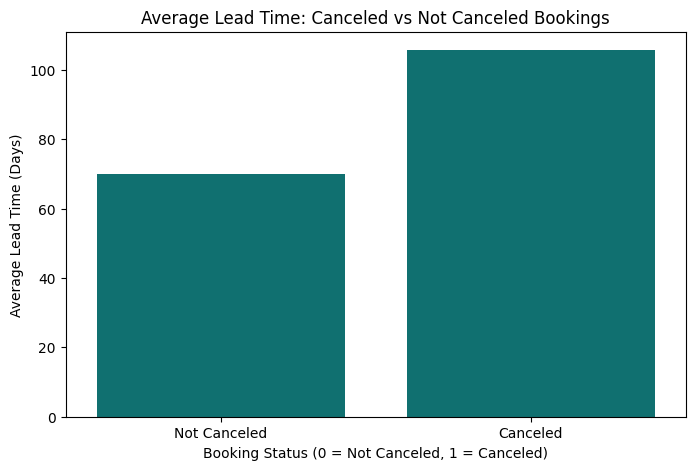

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

avg_lead_time = df.groupby('is_canceled')['lead_time'].mean().reset_index()

print("Average Lead Time (0 = Not Canceled, 1 = Canceled):")
print(avg_lead_time)

# Visualizing the result
plt.figure(figsize=(8, 5))

sns.barplot(x='is_canceled', y='lead_time', data=avg_lead_time, color='teal')
plt.title('Average Lead Time: Canceled vs Not Canceled Bookings')
plt.xlabel('Booking Status (0 = Not Canceled, 1 = Canceled)')
plt.ylabel('Average Lead Time (Days)')
plt.xticks([0, 1], ['Not Canceled', 'Canceled']) 
plt.show()

### Q2. Which month has the highest number of bookings?


Bookings per Month:
        month  bookings
11    January      4693
8    February      6098
5       March      7513
3       April      7908
2         May      8355
4        June      7765
1        July     10057
0      August     11257
7   September      6690
6     October      6934
10   November      4995
9    December      5131


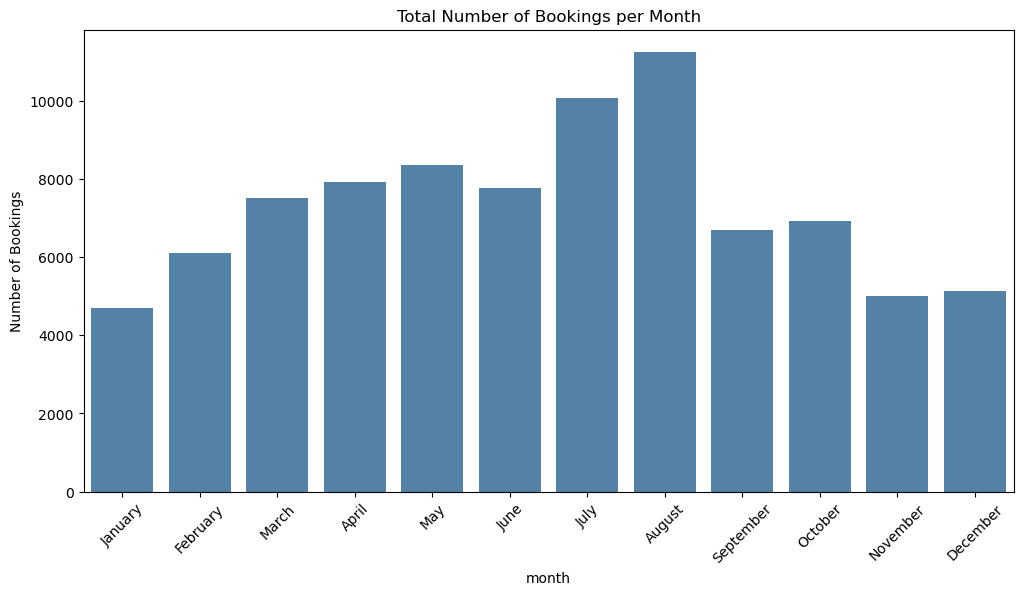

In [43]:
monthly_bookings = df['arrival_date_month'].value_counts().reset_index()
monthly_bookings.columns = ['month', 'bookings']

# Sort months chronologically
months_order = ['January', 'February', 'March', 'April', 'May', 'June', 
                'July', 'August', 'September', 'October', 'November', 'December']
monthly_bookings['month'] = pd.Categorical(monthly_bookings['month'], categories=months_order, ordered=True)
monthly_bookings = monthly_bookings.sort_values('month')

print("\nBookings per Month:")
print(monthly_bookings)

plt.figure(figsize=(12, 6))
sns.barplot(x='month', y='bookings', data=monthly_bookings, color='steelblue')
plt.title('Total Number of Bookings per Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.show()

### Q3. What is the distribution of ADR (Average Daily Rate) across different customer types?

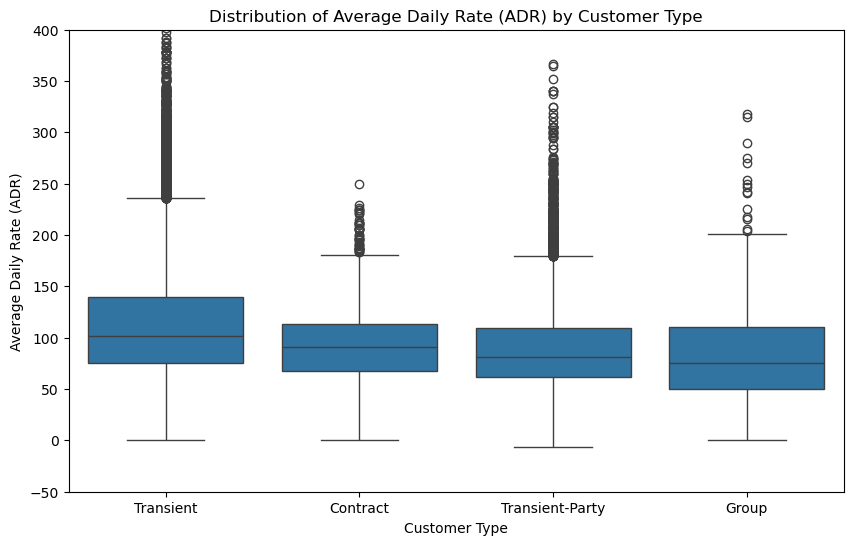

In [44]:
plt.figure(figsize=(10, 6))

# Added hue='customer_type' to fix the palette warning
sns.boxplot(x='customer_type', y='adr', data=df)

plt.title('Distribution of Average Daily Rate (ADR) by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Average Daily Rate (ADR)')

plt.ylim(-50, 400) 

plt.show()

### Q4. How many bookings had special requests, and what is the average number of special requests per booking?

Total bookings with special requests: 43502
Average special requests per booking: 0.70


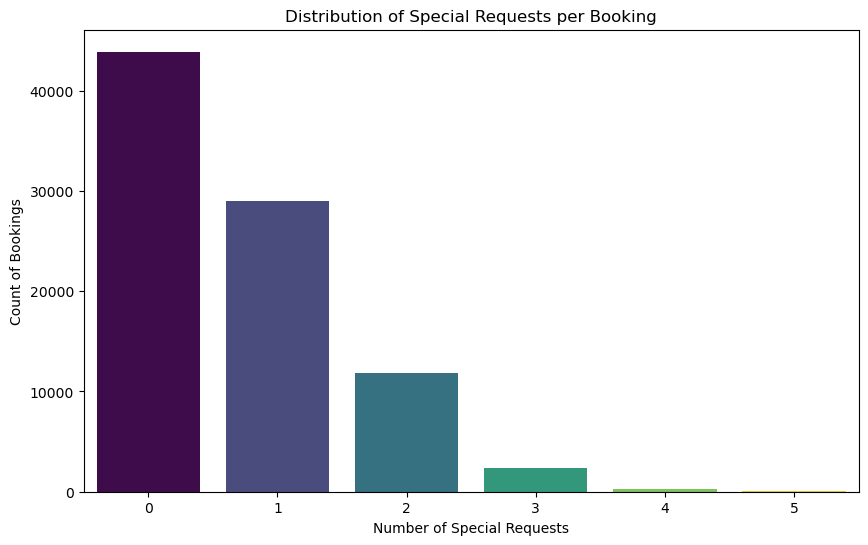

In [57]:
bookings_with_requests = (df['total_of_special_requests'] > 0).sum()

avg_requests = df['total_of_special_requests'].mean()

print(f"Total bookings with special requests: {bookings_with_requests}")
print(f"Average special requests per booking: {avg_requests:.2f}")

plt.figure(figsize=(10, 6))

sns.countplot(x='total_of_special_requests', hue='total_of_special_requests', data=df, palette='viridis', legend=False)

plt.title('Distribution of Special Requests per Booking')
plt.xlabel('Number of Special Requests')
plt.ylabel('Count of Bookings')

plt.show()

### Q5. What is the cancellation rate for each market segment?

Cancellation Rate by Market Segment:


,market_segment,cancellation_rate
0,Undefined,100.000000
1,Online TA,35.346197
2,Groups,27.013355
3,Aviation,19.823789
4,Offline TA/TO,14.853481
5,Direct,14.715351
6,Complementary,12.535613
7,Corporate,12.108262


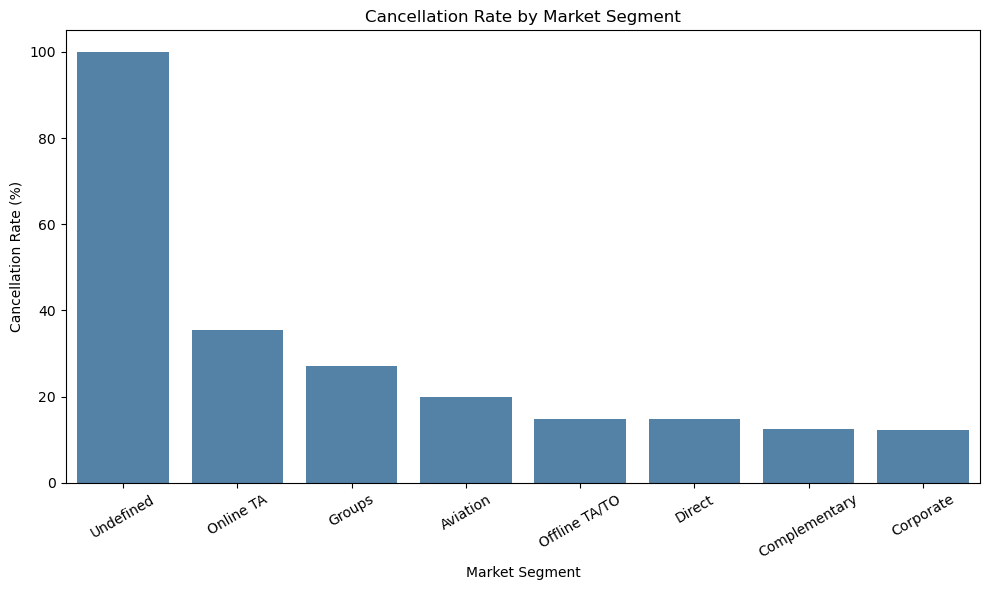

In [46]:
cancellation_by_segment = (
    df.groupby('market_segment')['is_canceled']
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .reset_index(name='cancellation_rate')
)

print("Cancellation Rate by Market Segment:")
display(cancellation_by_segment)

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(
    data=cancellation_by_segment,
    x='market_segment',
    y='cancellation_rate',
    color='steelblue'
)
plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Q6. Which distribution channel has the highest average ADR?

Average ADR by Distribution Channel:
  distribution_channel         adr
2                  GDS  120.317845
1               Direct  109.133604
3                TA/TO  108.559116
0            Corporate   68.515682
4            Undefined   46.240000


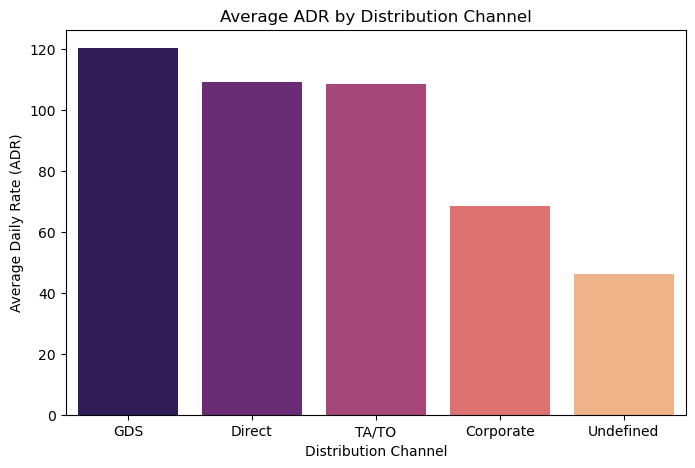

In [47]:
channel_adr = df.groupby('distribution_channel')['adr'].mean().reset_index()

channel_adr = channel_adr.sort_values('adr', ascending=False)

print("Average ADR by Distribution Channel:")
print(channel_adr)

plt.figure(figsize=(8, 5))
sns.barplot(x='distribution_channel', y='adr', hue='distribution_channel', data=channel_adr, palette='magma')

plt.title('Average ADR by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Average Daily Rate (ADR)')

plt.show()

### Q7. What is the correlation between lead time and the length of stay?

Correlation between Lead Time and Length of Stay: 0.3183


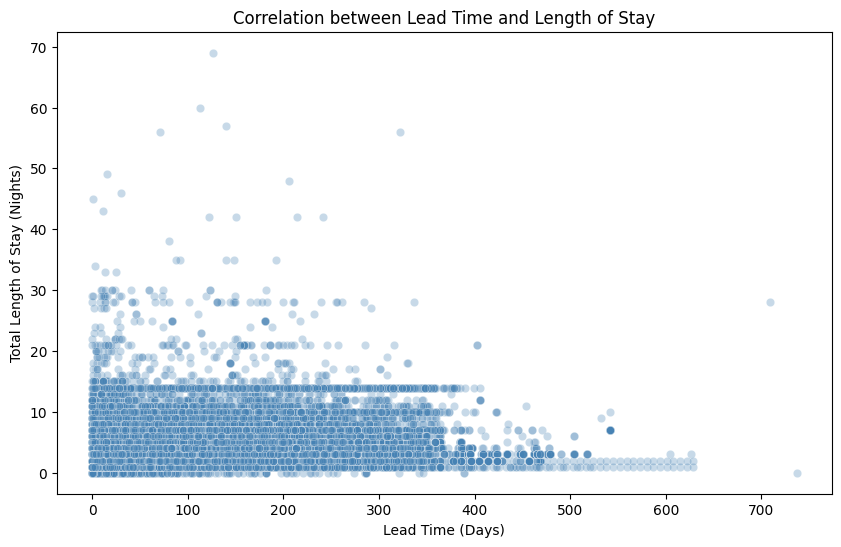

In [12]:
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

correlation = df[['lead_time', 'total_stay']].corr().loc['lead_time', 'total_stay']

print(f"Correlation between Lead Time and Length of Stay: {correlation:.4f}")

plt.figure(figsize=(10, 6))
sns.scatterplot(x='lead_time', y='total_stay', data=df, alpha=0.3, color='steelblue')

plt.title('Correlation between Lead Time and Length of Stay')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Total Length of Stay (Nights)')

plt.show()

### Q8.	How many bookings include children and/or babies?

Total bookings that include children and/or babies: 9103
Bookings with children: 8364
Bookings with babies: 914


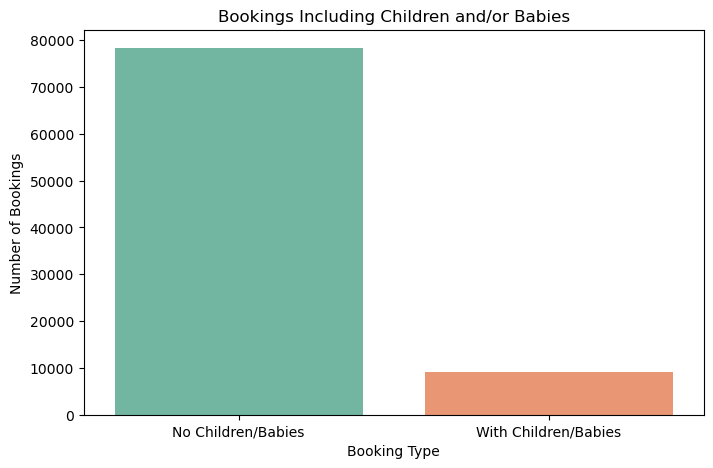

<Figure size 640x480 with 0 Axes>

In [58]:
family_bookings = df[(df['children'] > 0) | (df['babies'] > 0)]

total_family_bookings = len(family_bookings)

print(f"Total bookings that include children and/or babies: {total_family_bookings}")

with_children = (df['children'] > 0).sum()
with_babies = (df['babies'] > 0).sum()

print(f"Bookings with children: {with_children}")
print(f"Bookings with babies: {with_babies}")

df['has_children_babies'] = (df['children'] > 0) | (df['babies'] > 0)
df['has_children_babies_label'] = df['has_children_babies'].map({True: 'With Children/Babies', False: 'No Children/Babies'})

plt.figure(figsize=(8, 5))
sns.countplot(x='has_children_babies_label', hue='has_children_babies_label', data=df, palette='Set2', legend=False)
plt.title('Bookings Including Children and/or Babies')
plt.xlabel('Booking Type')
plt.ylabel('Number of Bookings')
plt.show()
plt.tight_layout()
plt.show()


### Q9.	What is the average lead time for repeated guests compared to new guests?

Average Lead Time (0 = New Guest, 1 = Repeated Guest):
   is_repeated_guest  lead_time
0                  0  82.442255
1                  1  17.160469


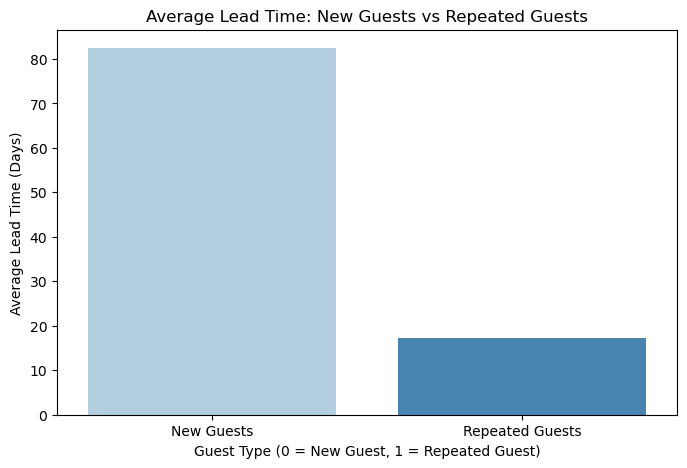

In [49]:
repeated_lead_time = df.groupby('is_repeated_guest')['lead_time'].mean().reset_index()

print("Average Lead Time (0 = New Guest, 1 = Repeated Guest):")
print(repeated_lead_time)

plt.figure(figsize=(8, 5))

sns.barplot(x='is_repeated_guest', y='lead_time', hue='is_repeated_guest', data=repeated_lead_time, palette='Blues', legend=False)

plt.title('Average Lead Time: New Guests vs Repeated Guests')
plt.xlabel('Guest Type (0 = New Guest, 1 = Repeated Guest)')
plt.ylabel('Average Lead Time (Days)')
plt.xticks([0, 1], ['New Guests', 'Repeated Guests'])

plt.show()

### Q10.	What is the most common combination of reserved room type and assigned room type?

In [15]:
room_combinations = (
    df.groupby(['reserved_room_type', 'assigned_room_type'])
      .size()
      .reset_index(name='booking_count')
      .sort_values('booking_count', ascending=False)
)

print("Top 10 combinations of reserved and assigned room types:")
print(room_combinations.head(10))

# Identify the most common combination
most_common_combination = room_combinations.iloc[0]

print("\nMost Common Combination:")
print(f"Reserved Room Type : {most_common_combination['reserved_room_type']}")
print(f"Assigned Room Type : {most_common_combination['assigned_room_type']}")
print(f"Number of Bookings  : {most_common_combination['booking_count']}")

Top 10 combinations of reserved and assigned room types:
   reserved_room_type assigned_room_type  booking_count
0                   A                  A          45879
29                  D                  D          15984
3                   A                  D           6410
40                  E                  E           5462
50                  F                  F           2636
60                  G                  G           1999
2                   A                  C           1256
4                   A                  E           1035
1                   A                  B            894
11                  B                  B            874

Most Common Combination:
Reserved Room Type : A
Assigned Room Type : A
Number of Bookings  : 45879


### Subjective Questions

### Q1. How does the lead time affect the likelihood of booking cancellations?

Cancellation Rate by Lead Time:


,lead_time_category,cancellation_rate
0,0-7 days,8.429851
1,8-30 days,25.367197
2,31-90 days,32.008442
3,91-180 days,34.983281
4,181-365 days,39.678571
5,365+ days,40.884956


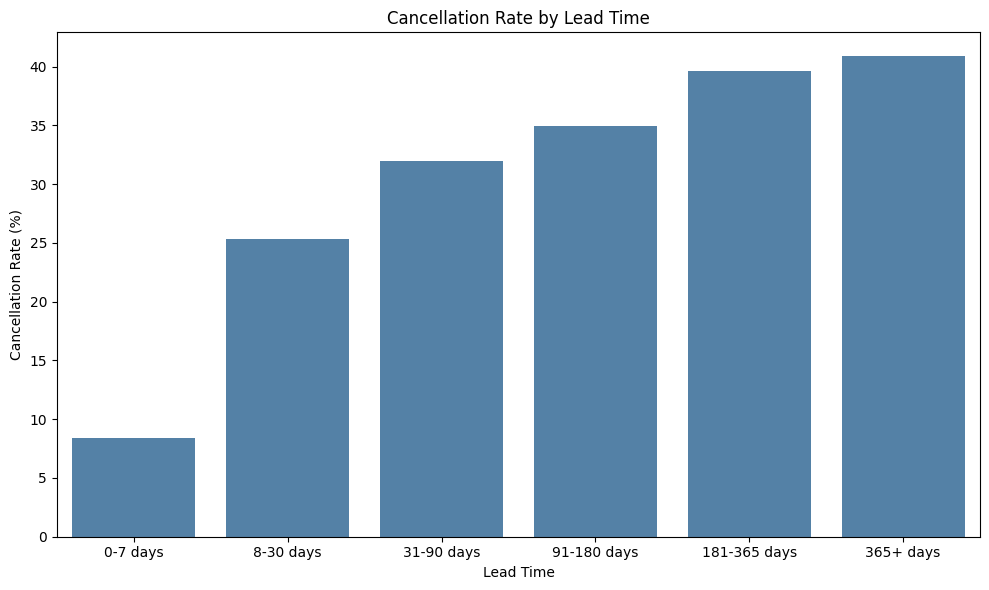

In [16]:
lead_time_bins = [0, 7, 30, 90, 180, 365, float('inf')]
lead_time_labels = ['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']

df['lead_time_category'] = pd.cut(
    df['lead_time'], bins=lead_time_bins, labels=lead_time_labels, include_lowest=True
)

lead_time_cancellation = (
    df.groupby('lead_time_category', observed=False)['is_canceled']
      .mean().mul(100).reset_index(name='cancellation_rate')
)

print("Cancellation Rate by Lead Time:")
display(lead_time_cancellation)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=lead_time_cancellation,
    x='lead_time_category',
    y='cancellation_rate',
    color='steelblue'
)
plt.title('Cancellation Rate by Lead Time')
plt.xlabel('Lead Time')
plt.ylabel('Cancellation Rate (%)')
plt.tight_layout()
plt.show()

### Q2. What impact do special requests have on booking cancellations?

Cancellation Rate by Number of Special Requests:


,total_of_special_requests,cancellation_rate
0,0,33.202716
1,1,22.411000
2,2,21.291907
3,3,17.134225
4,4,10.625000
5,5,5.555556


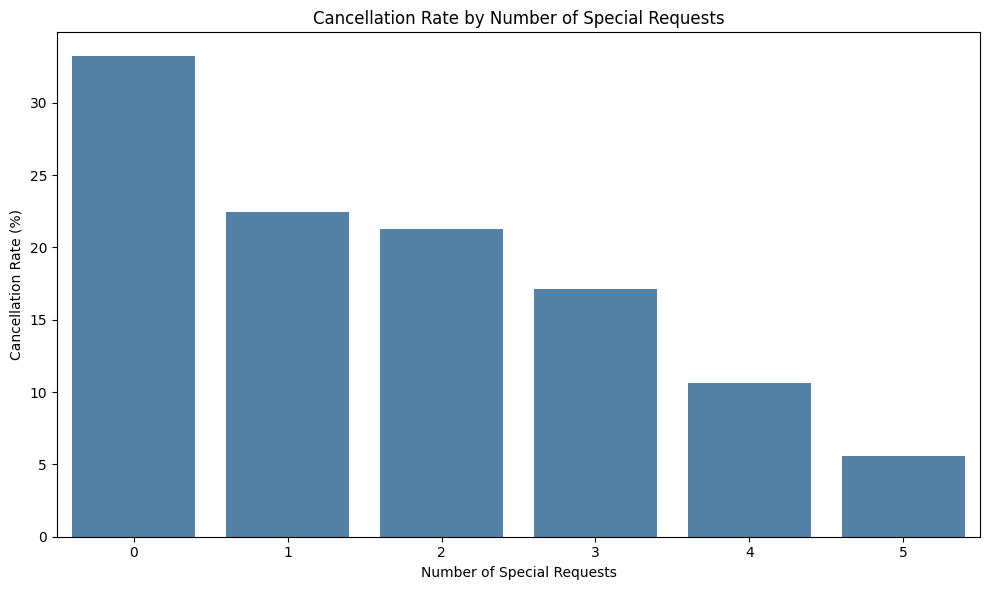

In [17]:
special_requests_cancellation = (
    df.groupby('total_of_special_requests')['is_canceled']
      .mean().mul(100).reset_index(name='cancellation_rate')
      .sort_values('total_of_special_requests')
)

print("Cancellation Rate by Number of Special Requests:")
display(special_requests_cancellation)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=special_requests_cancellation,
    x='total_of_special_requests',
    y='cancellation_rate',
    color='steelblue'
)
plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate (%)')
plt.tight_layout()
plt.show()

### Q3. What trends can be observed in the booking behavior of international guests compared to domestic guests?

Booking Behavior: International vs Domestic Guests


,guest_origin,booking_count,average_lead_time,average_adr,average_length_of_stay,cancellation_rate
0,Domestic,27453,65.101228,95.839512,3.088369,35.664590
1,International,59491,87.152679,111.523589,3.888874,23.869157
2,Unknown,452,22.482301,61.323164,2.581858,7.522124


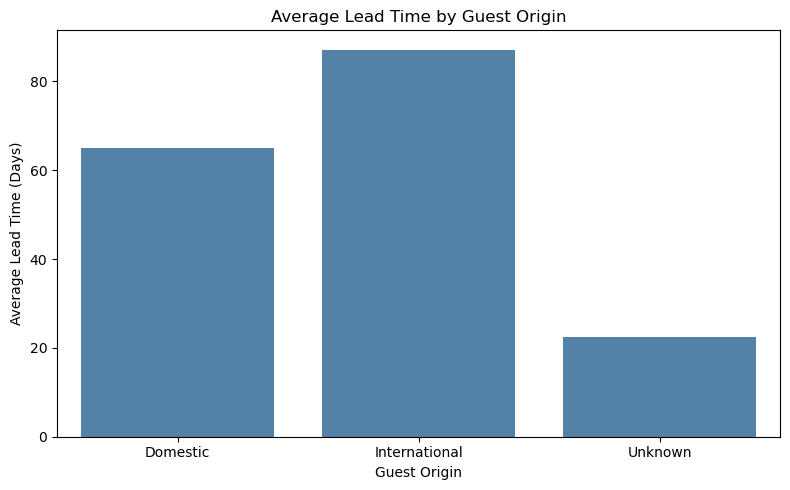

In [50]:
# Classify guests based on country.
# Because the hotel is located in Portugal, PRT is treated as domestic.
df['guest_origin'] = df['country'].apply(
    lambda x: 'Domestic' if x == 'PRT'
    else ('Unknown' if x == 'Unknown' else 'International')
)

df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

guest_origin_analysis = (
    df.groupby('guest_origin')
      .agg(
          booking_count=('is_canceled', 'size'),
          average_lead_time=('lead_time', 'mean'),
          average_adr=('adr', 'mean'),
          average_length_of_stay=('total_stay', 'mean'),
          cancellation_rate=('is_canceled', 'mean')
      )
      .reset_index()
)

guest_origin_analysis['cancellation_rate'] *= 100

print("Booking Behavior: International vs Domestic Guests")
display(guest_origin_analysis)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=guest_origin_analysis,
    x='guest_origin',
    y='average_lead_time',
    color='steelblue'
)
plt.title('Average Lead Time by Guest Origin')
plt.xlabel('Guest Origin')
plt.ylabel('Average Lead Time (Days)')
plt.tight_layout()
plt.show()

### Q4. What is the impact of the day of the week on booking cancellations?

Cancellation Rate by Day of the Week:


,arrival_day_of_week,cancellation_rate
1,Monday,26.750918
5,Tuesday,24.320887
6,Wednesday,25.513820
4,Thursday,27.740148
0,Friday,30.538070
2,Saturday,30.095311
3,Sunday,26.580185


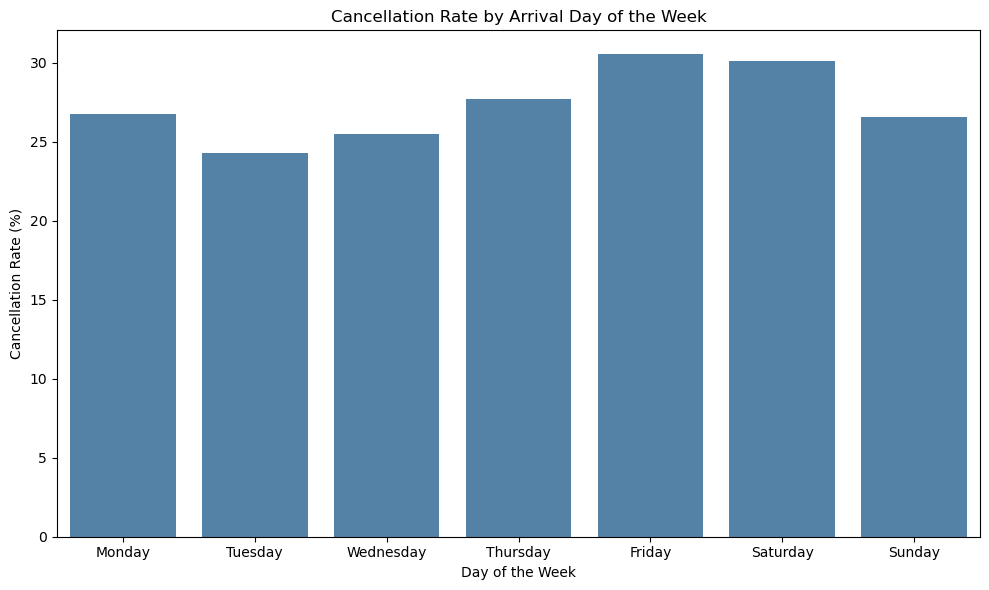

In [51]:
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str)
)
df['arrival_day_of_week'] = df['arrival_date'].dt.day_name()

day_cancellation = (
    df.groupby('arrival_day_of_week')['is_canceled']
      .mean().mul(100).reset_index(name='cancellation_rate')
)

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_cancellation['arrival_day_of_week'] = pd.Categorical(
    day_cancellation['arrival_day_of_week'], categories=day_order, ordered=True
)
day_cancellation = day_cancellation.sort_values('arrival_day_of_week')

print("Cancellation Rate by Day of the Week:")
display(day_cancellation)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=day_cancellation,
    x='arrival_day_of_week',
    y='cancellation_rate',
    color='steelblue'
)
plt.title('Cancellation Rate by Arrival Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Cancellation Rate (%)')
plt.tight_layout()
plt.show()

### Q5. What are the most common countries for international guests, and how do their booking patterns compare to domestic guests?

Top 5 International Countries:


country
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
Name: count, dtype: int64

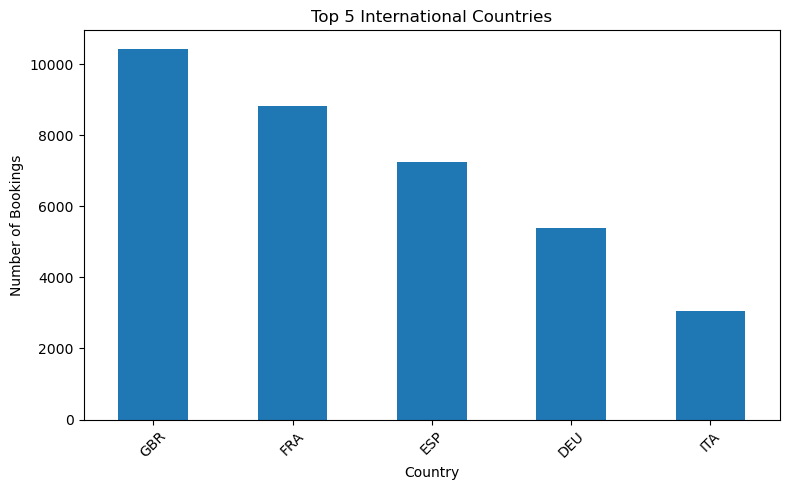

Domestic vs International Booking Behavior:


,average_lead_time,average_adr,average_length_of_stay,cancellation_rate
guest_origin,,,,
Domestic,65.101228,95.839512,3.088369,35.664590
International,87.152679,111.523589,3.888874,23.869157


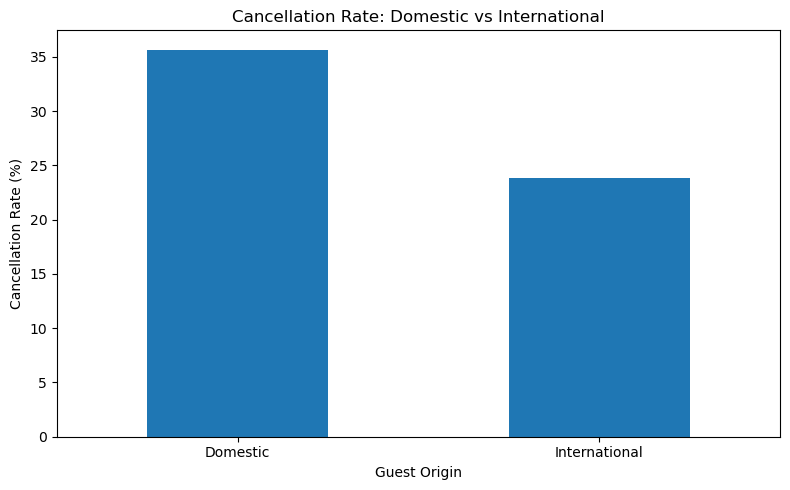

In [52]:
# Top 5 international countries-
top_countries = df[(df['country'] != 'PRT') & (df['country'] != 'Unknown')]['country'].value_counts().head(5)

print("Top 5 International Countries:")
display(top_countries)

top_countries.plot(kind='bar', figsize=(8, 5), title='Top 5 International Countries')
plt.xlabel('Country')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Domestic vs International comparison
comparison = (
    df[df['guest_origin'] != 'Unknown']
      .groupby('guest_origin')
      .agg(
          average_lead_time=('lead_time', 'mean'),
          average_adr=('adr', 'mean'),
          average_length_of_stay=('total_stay', 'mean'),
          cancellation_rate=('is_canceled', 'mean')
      )
)
comparison['cancellation_rate'] *= 100

print("Domestic vs International Booking Behavior:")
display(comparison)

comparison['cancellation_rate'].plot(kind='bar', figsize=(8, 5), title='Cancellation Rate: Domestic vs International')
plt.xlabel('Guest Origin')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Time Series Analysis

Time Series - Monthly Bookings Trend:
    arrival_date_year arrival_date_month  booking_count
2                2015               July           1674
0                2015             August           2453
5                2015          September           2839
4                2015            October           2700
3                2015           November           1665
1                2015           December           1982
10               2016            January           1849
9                2016           February           2806
13               2016              March           3831
6                2016              April           3770
14               2016                May           3780
12               2016               June           3517
11               2016               July           3851
7                2016             August           4423
17               2016          September           3851
16               2016            October           4234
15        

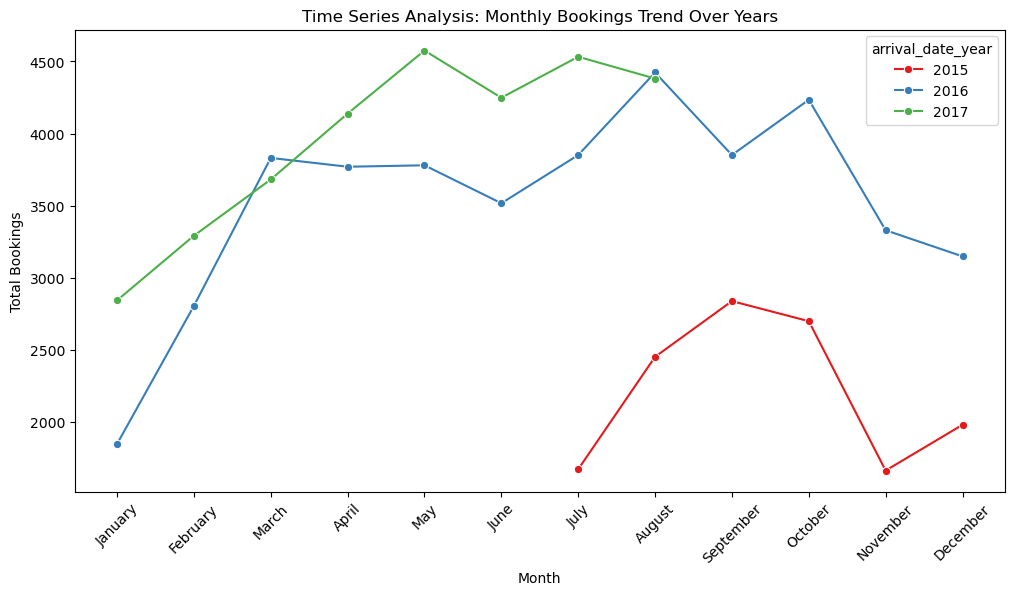

In [53]:
monthly_time_series = df.groupby(['arrival_date_year', 'arrival_date_month']).size().reset_index(name='booking_count')


month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_time_series['arrival_date_month'] = pd.Categorical(monthly_time_series['arrival_date_month'], categories=month_order, ordered=True)
monthly_time_series = monthly_time_series.sort_values(['arrival_date_year', 'arrival_date_month'])

print("Time Series - Monthly Bookings Trend:")
print(monthly_time_series)

plt.figure(figsize=(12, 6))
sns.lineplot(x='arrival_date_month', y='booking_count', hue='arrival_date_year', data=monthly_time_series, marker='o', palette='Set1')
plt.title('Time Series Analysis: Monthly Bookings Trend Over Years')
plt.xlabel('Month')
plt.ylabel('Total Bookings')
plt.xticks(rotation=45)
plt.show()

## 5. Segmentation Analysis: Identifying and analysing different customer segments

The customer segments are compared using average ADR, average length of stay, average lead time and cancellation rate. This helps identify which customer types generate more revenue and which segments present higher cancellation risk.

Segmentation Analysis by Customer Type:
     customer_type         adr  total_stay   lead_time  cancellation_rate_pct
0         Contract   92.753036    6.034406  109.225231              16.310927
1            Group   84.361949    2.920956   51.584559               9.926471
2        Transient  110.135859    3.578599   73.427236              30.105854
3  Transient-Party   87.675056    3.339729  113.032574              15.238339


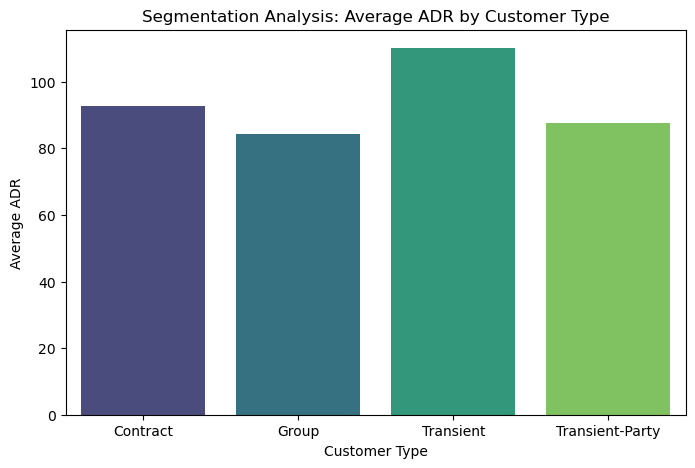

In [54]:
segmentation_analysis = df.groupby('customer_type').agg({
    'adr': 'mean',
    'total_stay': 'mean',
    'lead_time': 'mean',
    'is_canceled': 'mean'
}).reset_index()

segmentation_analysis['cancellation_rate_pct'] = segmentation_analysis['is_canceled'] * 100
print("Segmentation Analysis by Customer Type:")
print(segmentation_analysis[['customer_type', 'adr', 'total_stay', 'lead_time', 'cancellation_rate_pct']])

# Visualizing Segmentation ADR
plt.figure(figsize=(8, 5))
sns.barplot(x='customer_type', y='adr', hue='customer_type', data=segmentation_analysis, palette='viridis', legend=False)
plt.title('Segmentation Analysis: Average ADR by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Average ADR')
plt.show()

## 6. Booking and Cancellation Analysis: Examining booking attributes and their impact on cancellations and ADR.

Average ADR by Market Segment:
market_segment
Online TA        118.171606
Direct           116.579429
Aviation         100.170396
Offline TA/TO     81.764191
Groups            74.864284
Corporate         68.151246
Undefined         15.000000
Complementary      3.049245
Name: adr, dtype: float64


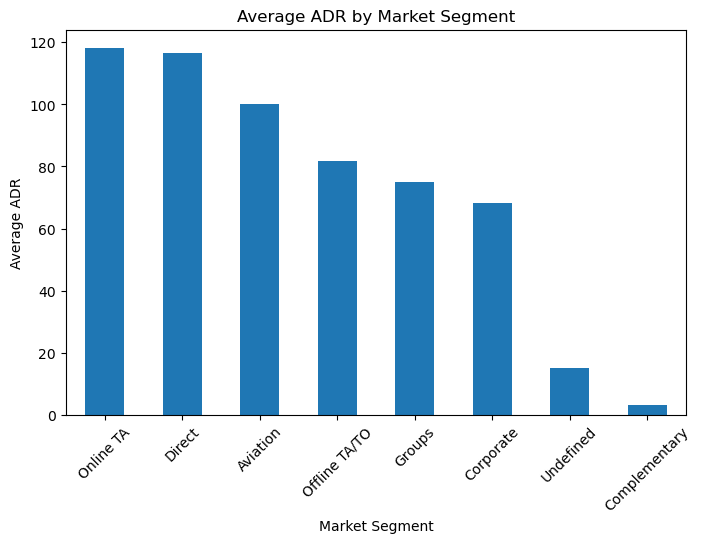

In [55]:
adr_by_segment = df.groupby('market_segment')['adr'].mean().sort_values(ascending=False)

print("Average ADR by Market Segment:")
print(adr_by_segment)

adr_by_segment.plot(
    kind='bar',
    figsize=(8, 5),
    title='Average ADR by Market Segment'
)

plt.xlabel('Market Segment')
plt.ylabel('Average ADR')
plt.xticks(rotation=45)
plt.show()

## 7. Actionable Insights: Providing recommendations based on the analysis to improve hotel operations and customer satisfaction.

## Actionable Insights

1. **Reduce risk from long-lead bookings:** Cancellation rates rise from **8.43%** for bookings made 0–7 days before arrival to **40.88%** for bookings made more than 365 days in advance. The hotel can use confirmation reminders, deposits or differentiated cancellation policies for high-risk long-lead bookings.

2. **Use market-segment-specific cancellation strategies:** Cancellation behavior varies across market segments. The hotel should monitor high-cancellation segments and consider targeted policies or incentives rather than applying one cancellation strategy to every segment.

3. **Target domestic and international guests differently:** Domestic and international guests differ in lead time, ADR, length of stay and cancellation behavior. Separate marketing campaigns, pricing strategies and communication can therefore improve targeting.

4. **Plan inventory around popular room assignments:** The most common reserved-to-assigned room combination is **A → A**, with **45,879 bookings**. Maintaining adequate availability of popular room types can reduce unnecessary room changes and support guest satisfaction.

5. **Encourage booking commitment through personalization:** Bookings with more special requests tend to have lower cancellation rates. The hotel can encourage guests to communicate preferences early, while using the finding as a behavioral signal rather than assuming special requests directly cause lower cancellations.

6. **Focus on repeat guests as a valuable segment:** Repeated guests have a much shorter average lead time than new guests. The hotel can use loyalty programs and personalized offers to encourage repeat visits and strengthen retention.

7. **Use ADR differences for revenue management:** ADR varies across customer types, market segments and distribution channels. Pricing and channel strategies should be adjusted based on both revenue potential and cancellation risk.

8. **Monitor seasonal demand:** Monthly booking patterns vary across the year. The hotel can use these trends to plan staffing, room inventory, promotions and pricing during high- and low-demand periods.